In [9]:
from pathlib import Path
import json
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import sklearn
import xgboost
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings(
    "ignore",
    message=r"`sklearn\.utils\.parallel\.delayed` should be used",
)

pd.set_option("display.max_columns", None)
print(f"scikit-learn: {sklearn.__version__}")
print(f"xgboost:       {xgboost.__version__}")
print(f"shap:          {shap.__version__}")


scikit-learn: 1.8.0
xgboost:       3.2.0
shap:          0.51.0


# Body-fat model analysis

## Configuration

This notebook consumes the downloaded body-fat HPC results; it does not retrain
or reselect models. Random Forest and XGBoost are loaded from their serialized
estimators, while PySR is reconstructed from the validation-selected equation
saved by the HPC run. Analysis results are written under
`outputs/bodyfat/analysis/`.


In [10]:
HPC_ROOT = Path("hpc_results/bodyfat")
PREPARED_DIR = HPC_ROOT / "prepared"
OUTPUT_DIR = Path("outputs/bodyfat/analysis")

RANDOM_STATE = 42
SAVE_ARTIFACTS = True
BACKGROUND_SIZE = 50
DELETION_REPEATS = 20
NOISE_LEVELS = [0.0, 0.025, 0.05]
NOISE_REPEATS = 100
CONTINUITY_REPEATS = 20
RESPONSE_STABILITY_FRACTION = 0.05

MODEL_SPECS = {
    "Random Forest": {
        "root": HPC_ROOT / "random_forest_20260719_232404",
        "artifact": "rf_best.joblib",
        "manifest": "rf_manifest.json",
        "saved_predictions": "rf_test_predictions.csv",
        "prediction_column": "rf_predicted_bodyfat",
    },
    "XGBoost": {
        "root": HPC_ROOT / "xgboost_20260719_232404",
        "artifact": "xgb_best.joblib",
        "manifest": "xgb_manifest.json",
        "saved_predictions": "xgb_test_predictions.csv",
        "prediction_column": "xgb_predicted_bodyfat",
    },
    "PySR": {
        "root": HPC_ROOT / "pysr_20260719_232448",
        "artifact": None,
        "manifest": "pysr_manifest.json",
        "equation_metrics": "pysr_equation_metrics.csv",
        "equation_key": "best_validation_rmse",
        "saved_predictions": "pysr_test_predictions.csv",
        "prediction_column": "pysr_best_validation_rmse_predicted_bodyfat",
    },
}

print(f"Prepared data: {PREPARED_DIR.resolve()}")
print(f"HPC results:   {HPC_ROOT.resolve()}")
print(f"Output:        {OUTPUT_DIR.resolve()}")


Prepared data: C:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\hpc_results\bodyfat\prepared
HPC results:   C:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\hpc_results\bodyfat
Output:        C:\Users\jarra\OneDrive\Documents\Work\UWA\Year 4\Research Project\Project\outputs\bodyfat\analysis


**Feasibility and method mapping**

| Feynman section | Body-fat feasibility | Body-fat implementation |
|---|---|---|
| Predictive performance | Directly feasible | Same held-out $R^2$, RMSE, MAE, and predicted-vs-actual plots |
| Controlled synthetic data check (Correctness) | Not valid: body-fat is observational and has no known feature-level data-generating equation | Paper-supported **Single Deletion** check over the 13 raw measurements: recompute derived ratios after replacement, then compare output change with raw-feature SHAP |
| Noise sensitivity (Continuity) | Feasible with adaptation | Perturb raw measurements, recompute derived ratios, and report explanation similarity both overall and only where the model response remains nearly unchanged |
| Compactness snapshot | Feasible | Same 90% absolute-SHAP coverage count for every model, plus representation-specific descriptive sizes |

`Density` remains excluded because `BodyFat` is derived from it in this dataset.
The correctness replacement measures faithfulness to each fitted model, not
alignment with causal or clinical truth.


## Load the prepared data


In [11]:
required_prepared_files = [
    "X_train.csv",
    "X_test.csv",
    "y_train.csv",
    "y_test.csv",
    "preprocessing_manifest.json",
]
missing_prepared = [
    name for name in required_prepared_files
    if not (PREPARED_DIR / name).is_file()
]
if missing_prepared:
    raise FileNotFoundError(
        f"Prepared body-fat data is incomplete at {PREPARED_DIR.resolve()}. "
        f"Missing: {missing_prepared}"
    )

X_train = pd.read_csv(PREPARED_DIR / "X_train.csv", index_col=0)
X_test = pd.read_csv(PREPARED_DIR / "X_test.csv", index_col=0)
y_train = pd.read_csv(PREPARED_DIR / "y_train.csv", index_col=0)["BodyFat"]
y_test = pd.read_csv(PREPARED_DIR / "y_test.csv", index_col=0)["BodyFat"]
with (PREPARED_DIR / "preprocessing_manifest.json").open(
    "r", encoding="utf-8"
) as file:
    preprocessing_manifest = json.load(file)

FEATURE_COLUMNS = list(preprocessing_manifest["feature_columns"])
RAW_FEATURE_COLUMNS = list(preprocessing_manifest["raw_feature_columns"])
EXPLANATION_COLUMNS = RAW_FEATURE_COLUMNS.copy()
TARGET_COLUMN = preprocessing_manifest["target_column"]

if list(X_train.columns) != FEATURE_COLUMNS:
    raise ValueError("X_train columns do not match preprocessing_manifest.json.")
if list(X_test.columns) != FEATURE_COLUMNS:
    raise ValueError("X_test columns do not match preprocessing_manifest.json.")
if not X_train.index.equals(y_train.index):
    raise ValueError("X_train and y_train row indices do not align.")
if not X_test.index.equals(y_test.index):
    raise ValueError("X_test and y_test row indices do not align.")
for name, values in [
    ("X_train", X_train.to_numpy(dtype=float)),
    ("X_test", X_test.to_numpy(dtype=float)),
    ("y_train", y_train.to_numpy(dtype=float)),
    ("y_test", y_test.to_numpy(dtype=float)),
]:
    if not np.isfinite(values).all():
        raise ValueError(f"{name} contains missing or non-finite values.")

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")
print(f"Target:       {TARGET_COLUMN}")
print(f"Excluded:     {preprocessing_manifest['excluded_columns']}")
display(X_train.head())
display(y_train.describe().to_frame("BodyFat"))


Training set: (201, 15)
Test set:     (51, 15)
Target:       BodyFat
Excluded:     ['Density']


,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,ACratio,HTratio
source_row_index,,,,,,,,,,,,,,,
136,39.0,166.75,70.75,37.0,92.9,86.1,95.6,58.8,36.1,22.4,32.7,28.3,17.1,0.926803,1.625850
55,54.0,198.00,72.00,39.9,107.6,100.0,99.6,57.2,38.0,22.0,35.9,30.2,18.9,0.929368,1.741259
204,44.0,223.00,69.75,40.9,121.6,113.9,107.1,63.5,40.3,21.8,34.8,30.7,17.4,0.936678,1.686614
216,51.0,149.25,69.75,34.8,92.8,81.1,96.3,53.8,36.5,21.5,31.3,26.3,17.8,0.873922,1.789963
147,25.0,206.50,69.75,40.9,110.9,100.5,106.2,68.4,40.8,24.6,33.3,29.7,18.4,0.906222,1.552632


,BodyFat
count,201.000000
mean,19.435821
std,8.696517
min,0.000000
25%,12.400000
50%,19.600000
75%,25.800000
max,47.500000


## Load the fitted models and symbolic metadata

Unlike the Feynman notebook, this notebook loads the completed HPC artifacts.
It verifies that every run used the same prepared feature order. The PySR run
did not serialize a fitted estimator, so its validation-selected equation is
loaded from the manifest and evaluated directly.


In [12]:
class SavedPySREquation:
    """Prediction wrapper for the equation selected during the HPC run."""

    def __init__(self, equation, feature_names):
        self.equation = str(equation)
        self.feature_names = list(feature_names)

    def predict(self, rows):
        frame = pd.DataFrame(rows, columns=self.feature_names)
        namespace = {name: frame[name] for name in self.feature_names}
        namespace["square"] = np.square
        prediction = pd.eval(
            self.equation, local_dict=namespace, engine="python"
        )
        return np.asarray(prediction, dtype=float).ravel()


models = {}
model_manifests = {}
load_seconds = {}
pysr_selected = None

for model_name, spec in MODEL_SPECS.items():
    run_root = spec["root"]
    manifest_path = run_root / spec["manifest"]
    prediction_path = run_root / spec["saved_predictions"]
    required_paths = [manifest_path, prediction_path]
    if spec["artifact"] is not None:
        required_paths.append(run_root / spec["artifact"])
    if "equation_metrics" in spec:
        required_paths.append(run_root / spec["equation_metrics"])
    missing = [str(path) for path in required_paths if not path.is_file()]
    if missing:
        raise FileNotFoundError(
            f"Downloaded HPC results are incomplete for {model_name}: {missing}"
        )

    with manifest_path.open("r", encoding="utf-8") as file:
        manifest = json.load(file)
    if list(manifest.get("feature_names", [])) != FEATURE_COLUMNS:
        raise ValueError(f"Feature order mismatch in {manifest_path}.")

    start = time.perf_counter()
    if model_name == "PySR":
        representative = manifest["representative_equations"][
            spec["equation_key"]
        ]
        pysr_selected = pd.Series(representative)
        pysr_equations = pd.read_csv(run_root / spec["equation_metrics"])
        selected_rows = pysr_equations.loc[
            (pysr_equations["label"] == representative["label"])
            & (pysr_equations["equation_index"] == representative["equation_index"])
        ]
        if len(selected_rows) != 1:
            raise ValueError("Could not uniquely locate the selected PySR equation.")
        if selected_rows.iloc[0]["equation"] != representative["equation"]:
            raise ValueError("PySR manifest and equation table disagree.")
        models[model_name] = SavedPySREquation(
            representative["equation"], FEATURE_COLUMNS
        )
    else:
        models[model_name] = joblib.load(run_root / spec["artifact"])
        if model_name == "Random Forest":
            # Avoid duplicate joblib worker warnings under local sklearn 1.8.
            models[model_name].n_jobs = 1
    load_seconds[model_name] = time.perf_counter() - start
    model_manifests[model_name] = manifest
    print(f"{model_name} loaded in {load_seconds[model_name]:.3f} seconds")

print("Selected PySR run:", pysr_selected["label"])
print("Selected PySR equation:")
print(pysr_selected["equation"])


Random Forest loaded in 0.118 seconds
XGBoost loaded in 0.003 seconds
PySR loaded in 0.031 seconds
Selected PySR run: ps50_p20_ni200_par0.01_adp1000
Selected PySR equation:
((-272.58493 * Wrist) + square(Abdomen)) / (Weight + (Neck - Biceps))


c:\Users\jarra\miniconda3\envs\xai-compare\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeRegressor from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\jarra\miniconda3\envs\xai-compare\Lib\site-packages\sklearn\base.py:463: InconsistentVersionWarning: Trying to unpickle estimator RandomForestRegressor from version 1.9.0 when using version 1.8.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [17]:
pd.set_option("display.max_colwidth", None)

columns = [
    "equation",
    "complexity",
    "variables_used",
    "validation_RMSE",
    "validation_R2",
    "RMSE",       # test RMSE
    "R2",         # test R²
]

display(
    pysr_equations
    .sort_values(["validation_RMSE", "complexity"])
    [columns]
    .head(20)
)

,equation,complexity,variables_used,validation_RMSE,validation_R2,RMSE,R2
0,((-272.58493 * Wrist) + square(Abdomen)) / (Weight + (Neck - Biceps)),12,Weight;Neck;Abdomen;Biceps;Wrist,4.206592,0.741483,3.882883,0.675894
1,(square(Abdomen) + (Wrist * -272.08652)) / ((Weight + Neck) - Biceps),12,Weight;Neck;Abdomen;Biceps;Wrist,4.208082,0.741300,3.889882,0.674725
2,((Wrist * -272.08197) + square(Abdomen)) / (Weight - (Biceps - Neck)),12,Weight;Neck;Abdomen;Biceps;Wrist,4.208098,0.741298,3.889949,0.674713
3,((Wrist * -272.0704) + square(Abdomen)) / ((Weight + Neck) - Biceps),12,Weight;Neck;Abdomen;Biceps;Wrist,4.208140,0.741292,3.890119,0.674685
4,((Wrist * -272.0704) + square(Abdomen)) / (Weight + (Neck - Biceps)),12,Weight;Neck;Abdomen;Biceps;Wrist,4.208140,0.741292,3.890119,0.674685
5,((Abdomen + (-53.854958 - Wrist)) * 176.48988) / Weight,9,Weight;Abdomen;Wrist,4.215549,0.740381,3.848107,0.681674
6,((((0.45274663 / Wrist) - (Weight * 0.00011381)) * square(Biceps)) + -77.340454) + Abdomen,14,Weight;Abdomen;Biceps;Wrist,4.216528,0.740260,3.766891,0.694969
7,(Abdomen + (Biceps * (((Wrist * Weight) * -0.00021442476) - -0.99465495))) + -82.30379,13,Weight;Abdomen;Biceps;Wrist,4.219724,0.739866,3.693773,0.706696
8,(Abdomen + -82.29404) - ((((Weight * Wrist) * 0.0002143936) + -0.99425155) * Biceps),13,Weight;Abdomen;Biceps;Wrist,4.219740,0.739864,3.693724,0.706703
9,Abdomen - ((Biceps * (((Wrist * Weight) * 0.00021439047) - 0.99425924)) + 82.29474),13,Weight;Abdomen;Biceps;Wrist,4.219750,0.739863,3.693716,0.706705


## Analysis

### 1. Predictive performance

Following the predictive-performance method in Table 3 (p.16), the clean
held-out test set is summarized with $R^2$, RMSE, and MAE. Reloaded predictions
are checked against the predictions saved by each HPC run before reporting.


In [13]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "R2": r2_score(y_true, y_pred),
        "RMSE": np.sqrt(mse),
        "MAE": mean_absolute_error(y_true, y_pred),
    }


predictions = {}
clean_rows = []

for model_name, model in models.items():
    test_pred = np.asarray(model.predict(X_test), dtype=float).ravel()
    predictions[model_name] = {"test": test_pred}

    spec = MODEL_SPECS[model_name]
    saved = pd.read_csv(spec["root"] / spec["saved_predictions"])
    saved = saved.set_index("source_row_index").loc[X_test.index]
    saved_pred = saved[spec["prediction_column"]].to_numpy()
    if not np.allclose(test_pred, saved_pred, rtol=1e-6, atol=1e-8):
        raise ValueError(f"Reloaded predictions do not match saved {model_name} output.")

    clean_rows.append(
        {"Method": model_name, **regression_metrics(y_test, test_pred)}
    )

clean_performance = pd.DataFrame(clean_rows).set_index("Method")
metrics = clean_performance.copy()
display(clean_performance.round(6))


,R2,RMSE,MAE
Method,,,
Random Forest,0.633244,4.130470,3.440410
XGBoost,0.634849,4.121420,3.517166
PySR,0.675894,3.882883,3.255707


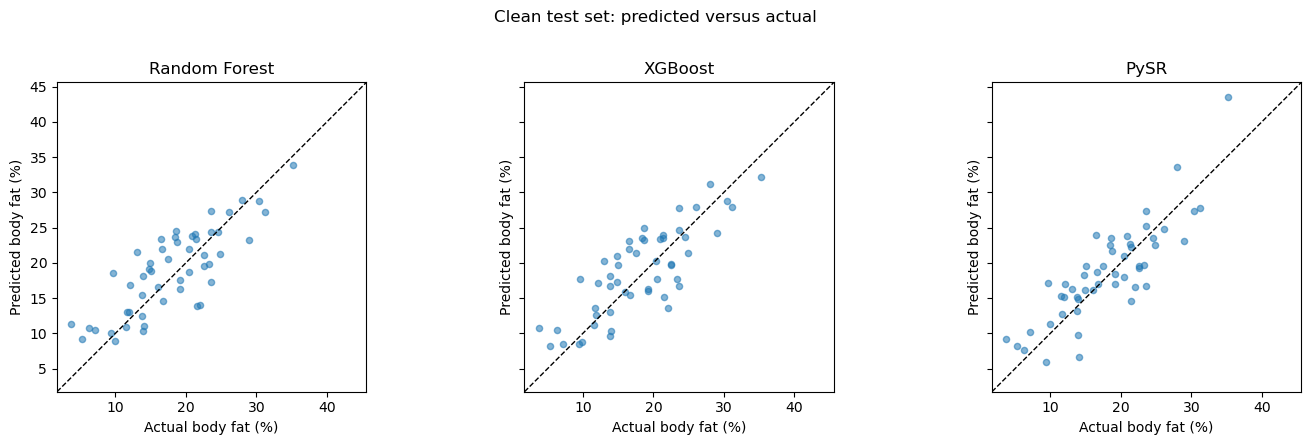

In [14]:
all_predictions = np.concatenate([
    values["test"] for values in predictions.values()
])

lower = min(y_test.min(), all_predictions.min())
upper = max(y_test.max(), all_predictions.max())

# Optional padding
padding = 0.05 * (upper - lower)
limits = (lower - padding, upper + padding)

fig, axes = plt.subplots(
    1,
    len(predictions),
    figsize=(4.8 * len(predictions), 4.3),
    sharex=True,
    sharey=True,
    squeeze=False,
)

for axis, (model_name, split_predictions) in zip(
    axes[0], predictions.items()
):
    test_pred = split_predictions["test"]

    axis.scatter(y_test, test_pred, alpha=0.55, s=20)
    axis.plot(limits, limits, "k--", linewidth=1)

    axis.set_xlim(limits)
    axis.set_ylim(limits)
    axis.set_aspect("equal", adjustable="box")

    axis.set_title(model_name)
    axis.set_xlabel("Actual body fat (%)")
    axis.set_ylabel("Predicted body fat (%)")

fig.suptitle("Clean test set: predicted versus actual", y=1.02)
plt.tight_layout()
plt.show()

### 2. Explanation correctness - adapted Single Deletion check

The Feynman controlled-synthetic check cannot be reproduced honestly because
body-fat has no known feature-level data-generating equation. Both the original
and replacement methods evaluate the paper's **Correctness** property.

All models are explained with model-agnostic permutation SHAP over the 13 raw
measurements. The prediction wrapper recomputes `ACratio` and `HTratio` before
calling each fitted 15-input model. Single Deletion uses the same representation:
one raw measurement is sampled from the training distribution and both ratios are
recomputed before prediction. A faithful
importance profile should rank features similarly to the resulting mean absolute
prediction changes. Spearman correlation is reported exactly as in the Feynman
ranking comparison. This preserves the deterministic ratios, although empirical
marginal replacements can still disrupt correlations among body measurements.


In [ ]:
def shap_matrix(values):
    if hasattr(values, "values"):
        values = values.values
    if isinstance(values, list):
        if len(values) != 1:
            raise ValueError("Expected one SHAP output for scalar regression.")
        values = values[0]
    values = np.asarray(values)
    if values.ndim == 3 and values.shape[-1] == 1:
        values = values[..., 0]
    if values.ndim != 2:
        raise ValueError(f"Expected a 2D SHAP matrix, received {values.shape}.")
    return values


def prepared_feature_frame(raw_rows):
    raw = pd.DataFrame(raw_rows, columns=EXPLANATION_COLUMNS).copy()
    if not np.isfinite(raw.to_numpy(dtype=float)).all():
        raise ValueError("Raw body-fat rows contain non-finite values.")
    if (raw[["Chest", "Thigh"]] == 0).any().any():
        raise ValueError("Chest and Thigh must be non-zero to derive ratios.")

    prepared = raw.copy()
    prepared["ACratio"] = prepared["Abdomen"] / prepared["Chest"]
    prepared["HTratio"] = prepared["Hip"] / prepared["Thigh"]
    return prepared[FEATURE_COLUMNS]


background = X_train[EXPLANATION_COLUMNS].sample(
    n=min(BACKGROUND_SIZE, len(X_train)),
    random_state=RANDOM_STATE,
)
explainers = {}
explainer_kinds = {}
clean_shap_values = {}
mean_abs_shap = {}


def model_prediction_function(model):
    def predict(rows):
        frame = prepared_feature_frame(rows)
        return np.asarray(model.predict(frame), dtype=float).ravel()
    return predict


def explain_rows(model_name, rows):
    explainer = explainers[model_name]
    values = explainer(
        rows,
        max_evals=2 * len(EXPLANATION_COLUMNS) + 1,
        silent=True,
    )
    return shap_matrix(values)


for model_name, model in models.items():
    masker = shap.maskers.Independent(
        background,
        max_samples=len(background),
    )
    explainer = shap.Explainer(
        model_prediction_function(model),
        masker,
        algorithm="permutation",
        feature_names=EXPLANATION_COLUMNS,
        seed=RANDOM_STATE,
    )
    explainer_kind = (
        "Permutation SHAP over 13 raw measurements; ratios recomputed"
    )

    explainers[model_name] = explainer
    explainer_kinds[model_name] = explainer_kind
    values = explain_rows(model_name, X_test[EXPLANATION_COLUMNS])
    clean_shap_values[model_name] = values
    mean_abs_shap[model_name] = np.mean(np.abs(values), axis=0)
    print(f"{model_name}: {explainer_kind}, SHAP shape {values.shape}")


Random Forest: Permutation SHAP over 13 raw measurements; ratios recomputed, SHAP shape (51, 13)


XGBoost: Permutation SHAP over 13 raw measurements; ratios recomputed, SHAP shape (51, 13)


PySR: Permutation SHAP over 13 raw measurements; ratios recomputed, SHAP shape (51, 13)


In [ ]:
deletion_rng = np.random.default_rng(RANDOM_STATE)
single_deletion_impact = {}
ranking_table = pd.DataFrame({"Feature": EXPLANATION_COLUMNS})
alignment_rows = []

for model_name, model in models.items():
    feature_impacts = []
    clean_prediction = predictions[model_name]["test"]

    for feature in EXPLANATION_COLUMNS:
        changes = []
        train_values = X_train[feature].to_numpy()
        for _ in range(DELETION_REPEATS):
            perturbed_raw = X_test[EXPLANATION_COLUMNS].copy()
            donor_indices = deletion_rng.integers(
                0, len(train_values), size=len(X_test)
            )
            perturbed_raw[feature] = train_values[donor_indices]
            perturbed = prepared_feature_frame(perturbed_raw)
            perturbed_prediction = np.asarray(
                model.predict(perturbed), dtype=float
            ).ravel()
            changes.append(
                np.mean(np.abs(perturbed_prediction - clean_prediction))
            )
        feature_impacts.append(np.mean(changes))

    deletion_vector = np.asarray(feature_impacts)
    shap_vector = mean_abs_shap[model_name]
    single_deletion_impact[model_name] = deletion_vector
    correlation = spearmanr(shap_vector, deletion_vector)

    shap_profile = shap_vector / max(shap_vector.sum(), np.finfo(float).eps)
    deletion_profile = deletion_vector / max(
        deletion_vector.sum(), np.finfo(float).eps
    )
    alignment_rows.append(
        {
            "Method": model_name,
            "Spearman correlation": correlation.statistic,
            "Spearman p-value": correlation.pvalue,
            "Normalized profile L1 distance": np.sum(
                np.abs(shap_profile - deletion_profile)
            ),
        }
    )

    ranking_table[f"{model_name} mean |SHAP|"] = shap_vector
    ranking_table[f"{model_name} SHAP rank"] = pd.Series(shap_vector).rank(
        method="min", ascending=False
    ).astype(int)
    ranking_table[f"{model_name} deletion impact"] = deletion_vector
    ranking_table[f"{model_name} deletion rank"] = pd.Series(
        deletion_vector
    ).rank(method="min", ascending=False).astype(int)

correctness_alignment = pd.DataFrame(alignment_rows).set_index("Method")
display(correctness_alignment.round(4))
display(ranking_table.round(6))


,Spearman correlation,Spearman p-value,Normalized profile L1 distance
Method,,,
Random Forest,0.9451,0.0,0.1151
XGBoost,0.9286,0.0,0.1408
PySR,1.0000,0.0,0.0334


,Feature,Random Forest mean |SHAP|,Random Forest SHAP rank,Random Forest deletion impact,Random Forest deletion rank,XGBoost mean |SHAP|,XGBoost SHAP rank,XGBoost deletion impact,XGBoost deletion rank,PySR mean |SHAP|,PySR SHAP rank,PySR deletion impact,PySR deletion rank
0,Age,0.308776,4,0.468321,4,0.828628,3,1.090277,3,0.000000,6,0.000000,6
1,Weight,0.218542,7,0.315486,7,0.100396,11,0.089512,12,2.551988,2,3.897020,2
2,Height,0.418541,3,0.583120,3,0.554600,6,0.772289,5,0.000000,6,0.000000,6
3,Neck,0.141085,10,0.227698,11,0.273874,7,0.323161,8,0.250146,5,0.268501,5
4,Chest,0.447900,2,1.218748,2,0.567495,5,1.387883,2,0.000000,6,0.000000,6
5,Abdomen,4.546990,1,6.886756,1,4.874565,1,7.703966,1,7.563988,1,11.412287,1
6,Hip,0.165755,8,0.306152,9,0.124913,10,0.221023,10,0.000000,6,0.000000,6
7,Thigh,0.133038,12,0.307198,8,0.219146,9,0.366166,7,0.000000,6,0.000000,6
8,Knee,0.139268,11,0.222422,12,0.244540,8,0.317198,9,0.000000,6,0.000000,6
9,Ankle,0.147209,9,0.253780,10,0.089439,12,0.134765,11,0.000000,6,0.000000,6


In [ ]:
print("Selected PySR expression:")
print(pysr_selected["equation"])

symbolic_structure = pd.DataFrame(
    [
        {
            "Method": "PySR",
            "Direct representation": "validation-selected symbolic equation",
            "Variables used": int(pysr_selected["n_variables_used"]),
            "Expression/generated-term count": int(pysr_selected["complexity"]),
        },
    ]
).set_index("Method")
display(symbolic_structure)


Selected PySR expression:
((-272.58493 * Wrist) + square(Abdomen)) / (Weight + (Neck - Biceps))


,Direct representation,Variables used,Expression/generated-term count
Method,,,
PySR,validation-selected symbolic equation,5,12


### 3. Noise sensitivity

This follows the Feynman extension of the paper's Stability for Slight
Variations method (pp.17, 23). Gaussian noise is scaled by each raw feature's
training standard deviation. Unlike the Feynman data, body-fat contains
deterministic derived ratios, so noise is applied only to raw measurements and
`ACratio`/`HTratio` are recomputed. Perturbed values are not clipped to the
training range: clipping would abruptly project legitimate test outliers back
into the training distribution at every non-zero noise level.

The paper says explanation similarity should only be interpreted when the model
response is nearly identical. Here that means an absolute prediction change no
larger than 5% of the training target standard deviation. Predictive robustness
is averaged over 100 paired noise draws, while the more expensive explanation
continuity calculation uses the first 20 paired draws. Reported intervals are
the empirical 2.5th and 97.5th percentiles across those perturbations.


In [ ]:
def row_cosine_similarity(reference, comparison):
    reference = np.asarray(reference)
    comparison = np.asarray(comparison)
    dots = np.sum(reference * comparison, axis=1)
    reference_norm = np.linalg.norm(reference, axis=1)
    comparison_norm = np.linalg.norm(comparison, axis=1)
    denominators = reference_norm * comparison_norm

    similarities = np.zeros(reference.shape[0], dtype=float)
    nonzero = denominators > np.finfo(float).eps
    similarities[nonzero] = dots[nonzero] / denominators[nonzero]
    both_zero = (
        (reference_norm <= np.finfo(float).eps)
        & (comparison_norm <= np.finfo(float).eps)
    )
    similarities[both_zero] = 1.0
    return np.clip(similarities, -1.0, 1.0)


noise_rng = np.random.default_rng(RANDOM_STATE)
noise_draws = [
    noise_rng.normal(size=(len(X_test), len(RAW_FEATURE_COLUMNS)))
    for _ in range(NOISE_REPEATS)
]
train_std = X_train[RAW_FEATURE_COLUMNS].std(axis=0, ddof=0).to_numpy()
response_stability_tolerance = (
    RESPONSE_STABILITY_FRACTION * y_train.std(ddof=0)
)
noise_rows = []


def noisy_bodyfat_rows(noise_level, standard_normal_noise):
    if noise_level == 0:
        return X_test.copy()

    expected_shape = (len(X_test), len(RAW_FEATURE_COLUMNS))
    if np.asarray(standard_normal_noise).shape != expected_shape:
        raise ValueError(
            f"Expected noise with shape {expected_shape}, received "
            f"{np.asarray(standard_normal_noise).shape}."
        )

    noisy_raw = pd.DataFrame(
        X_test[RAW_FEATURE_COLUMNS].to_numpy()
        + noise_level * standard_normal_noise * train_std,
        index=X_test.index,
        columns=RAW_FEATURE_COLUMNS,
    )
    if not np.isfinite(noisy_raw.to_numpy()).all():
        raise ValueError("Noise produced missing or non-finite measurements.")
    if (noisy_raw <= 0).any().any():
        raise ValueError(
            "Noise produced a non-positive anthropometric measurement; "
            "reduce the configured noise level instead of clipping the row."
        )

    noisy = X_test.copy()
    noisy.loc[:, RAW_FEATURE_COLUMNS] = noisy_raw
    noisy["ACratio"] = noisy["Abdomen"] / noisy["Chest"]
    noisy["HTratio"] = noisy["Hip"] / noisy["Thigh"]
    return noisy[FEATURE_COLUMNS]


zero_noise_check = noisy_bodyfat_rows(0.0, np.zeros_like(noise_draws[0]))
np.testing.assert_allclose(
    zero_noise_check.to_numpy(),
    X_test[FEATURE_COLUMNS].to_numpy(),
    rtol=0.0,
    atol=0.0,
)

for repeat_index, base_noise in enumerate(noise_draws):
    for noise_level in NOISE_LEVELS:
        noisy_test = noisy_bodyfat_rows(noise_level, base_noise)

        for model_name, model in models.items():
            noisy_prediction = np.asarray(
                model.predict(noisy_test), dtype=float
            ).ravel()
            prediction_change = np.abs(
                noisy_prediction - predictions[model_name]["test"]
            )
            stable_rows = prediction_change <= response_stability_tolerance

            evaluate_continuity = (
                noise_level == 0 or repeat_index < CONTINUITY_REPEATS
            )
            if evaluate_continuity:
                noisy_shap = (
                    clean_shap_values[model_name]
                    if noise_level == 0
                    else explain_rows(
                        model_name, noisy_test[EXPLANATION_COLUMNS]
                    )
                )
                cosine = row_cosine_similarity(
                    clean_shap_values[model_name], noisy_shap
                )
                mean_cosine = cosine.mean()
                stable_mean_cosine = (
                    cosine[stable_rows].mean()
                    if stable_rows.any()
                    else np.nan
                )
            else:
                mean_cosine = np.nan
                stable_mean_cosine = np.nan

            noise_rows.append(
                {
                    "Method": model_name,
                    "Noise repeat": repeat_index,
                    "Noise (% training SD)": 100 * noise_level,
                    "R2": r2_score(y_test, noisy_prediction),
                    "RMSE": np.sqrt(
                        mean_squared_error(y_test, noisy_prediction)
                    ),
                    "Mean absolute prediction change": (
                        prediction_change.mean()
                    ),
                    "Response-stable rows (%)": 100 * stable_rows.mean(),
                    "Mean SHAP cosine similarity": mean_cosine,
                    "Mean SHAP cosine similarity (response-stable rows)": (
                        stable_mean_cosine
                    ),
                }
            )

noise_run_results = pd.DataFrame(noise_rows)


def empirical_interval(values):
    finite = pd.Series(values).dropna()
    if finite.empty:
        return np.nan, np.nan
    return finite.quantile(0.025), finite.quantile(0.975)


noise_summary_rows = []
for (model_name, noise_percent), group in noise_run_results.groupby(
    ["Method", "Noise (% training SD)"], sort=False
):
    rmse_lower, rmse_upper = empirical_interval(group["RMSE"])
    stable_cosine_lower, stable_cosine_upper = empirical_interval(
        group["Mean SHAP cosine similarity (response-stable rows)"]
    )
    noise_summary_rows.append(
        {
            "Method": model_name,
            "Noise (% training SD)": noise_percent,
            "Noise repeats": len(group),
            "Continuity repeats": group[
                "Mean SHAP cosine similarity (response-stable rows)"
            ].notna().sum(),
            "R2": group["R2"].mean(),
            "RMSE": group["RMSE"].mean(),
            "RMSE 2.5%": rmse_lower,
            "RMSE 97.5%": rmse_upper,
            "Mean absolute prediction change": group[
                "Mean absolute prediction change"
            ].mean(),
            "Response-stable rows (%)": group[
                "Response-stable rows (%)"
            ].mean(),
            "Mean SHAP cosine similarity": group[
                "Mean SHAP cosine similarity"
            ].mean(),
            "Mean SHAP cosine similarity (response-stable rows)": group[
                "Mean SHAP cosine similarity (response-stable rows)"
            ].mean(),
            "Stable-response SHAP cosine 2.5%": stable_cosine_lower,
            "Stable-response SHAP cosine 97.5%": stable_cosine_upper,
        }
    )

noise_results = pd.DataFrame(noise_summary_rows).sort_values(
    ["Noise (% training SD)", "Method"]
).reset_index(drop=True)
print(
    "Response-stability tolerance: "
    f"{response_stability_tolerance:.4f} body-fat percentage points"
)
print(
    f"Predictive robustness: {NOISE_REPEATS} paired noise draws per level; "
    f"explanation continuity: {CONTINUITY_REPEATS} paired non-zero draws."
)
display(noise_results.round(6))


Response-stability tolerance: 0.4337 body-fat percentage points
Predictive robustness: 100 paired noise draws per level; explanation continuity: 20 paired non-zero draws.


,Method,Noise (% training SD),Noise repeats,Continuity repeats,R2,RMSE,RMSE 2.5%,RMSE 97.5%,Mean absolute prediction change,Response-stable rows (%),Mean SHAP cosine similarity,Mean SHAP cosine similarity (response-stable rows),Stable-response SHAP cosine 2.5%,Stable-response SHAP cosine 97.5%
0,PySR,0.0,100,100,0.675894,3.882883,3.882883,3.882883,0.000000,100.000000,1.000000,1.000000,1.000000,1.000000
1,Random Forest,0.0,100,100,0.633244,4.130470,4.130470,4.130470,0.000000,100.000000,1.000000,1.000000,1.000000,1.000000
2,XGBoost,0.0,100,100,0.634849,4.121420,4.121420,4.121420,0.000000,100.000000,1.000000,1.000000,1.000000,1.000000
3,PySR,2.5,100,20,0.673393,3.897623,3.825021,3.968238,0.222748,88.784314,0.992452,0.993849,0.983937,0.998970
4,Random Forest,2.5,100,20,0.632823,4.132466,4.041326,4.254188,0.226715,84.784314,0.984110,0.994964,0.990526,0.997368
5,XGBoost,2.5,100,20,0.645217,4.062050,3.956576,4.176383,0.289188,74.509804,0.991731,0.998036,0.996383,0.998765
6,PySR,5.0,100,20,0.667533,3.931814,3.785989,4.074466,0.445580,55.490196,0.981686,0.994221,0.980542,0.999032
7,Random Forest,5.0,100,20,0.627047,4.163985,3.982758,4.350982,0.445370,69.215686,0.966323,0.994824,0.990834,0.997468
8,XGBoost,5.0,100,20,0.636661,4.109880,3.925721,4.354006,0.515257,61.823529,0.978733,0.995125,0.986878,0.998617


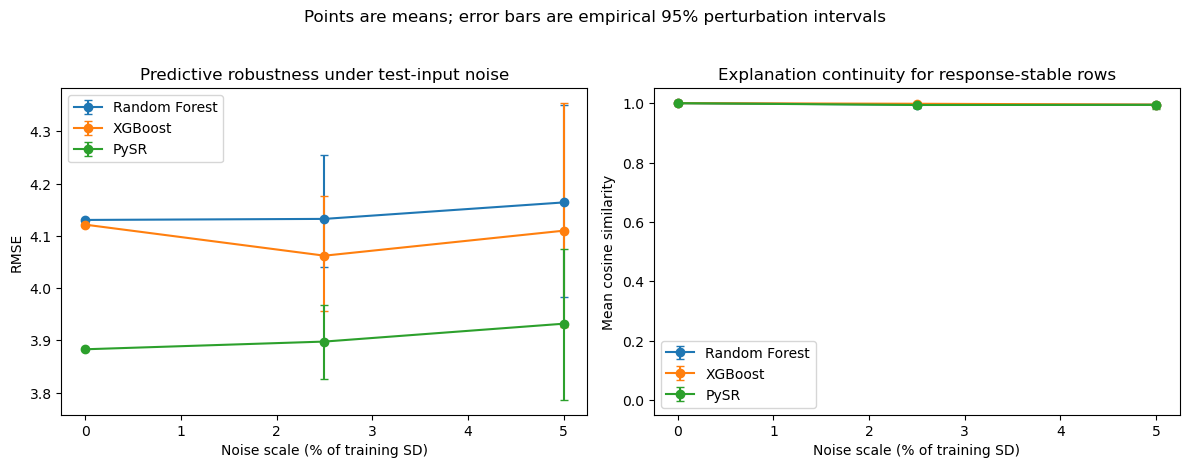

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for model_name in predictions:
    model_noise = noise_results[noise_results["Method"] == model_name]
    rmse = model_noise["RMSE"].to_numpy()
    rmse_interval = np.vstack(
        [
            rmse - model_noise["RMSE 2.5%"].to_numpy(),
            model_noise["RMSE 97.5%"].to_numpy() - rmse,
        ]
    )
    axes[0].errorbar(
        model_noise["Noise (% training SD)"],
        rmse,
        yerr=np.maximum(rmse_interval, 0.0),
        marker="o",
        capsize=3,
        label=model_name,
    )

    stable_cosine = model_noise[
        "Mean SHAP cosine similarity (response-stable rows)"
    ].to_numpy()
    cosine_interval = np.vstack(
        [
            stable_cosine
            - model_noise["Stable-response SHAP cosine 2.5%"].to_numpy(),
            model_noise["Stable-response SHAP cosine 97.5%"].to_numpy()
            - stable_cosine,
        ]
    )
    axes[1].errorbar(
        model_noise["Noise (% training SD)"],
        stable_cosine,
        yerr=np.maximum(cosine_interval, 0.0),
        marker="o",
        capsize=3,
        label=model_name,
    )

axes[0].set_title("Predictive robustness under test-input noise")
axes[0].set_xlabel("Noise scale (% of training SD)")
axes[0].set_ylabel("RMSE")
axes[0].legend()

axes[1].set_title("Explanation continuity for response-stable rows")
axes[1].set_xlabel("Noise scale (% of training SD)")
axes[1].set_ylabel("Mean cosine similarity")
axes[1].set_ylim(-0.05, 1.05)
axes[1].legend()

fig.suptitle(
    "Points are means; error bars are empirical 95% perturbation intervals",
    y=1.03,
)
plt.tight_layout()
plt.show()


### 4. Compactness snapshot

As in the Feynman notebook, features are ordered by absolute SHAP magnitude for
each test row and counted until they explain at least 90% of that row's total.
Since every body-fat model has a SHAP explanation, this common metric is
available for all three models. Direct representation descriptions are also
shown, but they are model-specific and are not comparable scores.


In [ ]:
def feature_counts_for_shap_coverage(values, coverage=0.90):
    absolute_values = np.abs(values)
    counts = []
    for row in absolute_values:
        total = row.sum()
        if total <= np.finfo(float).eps:
            counts.append(0)
            continue
        cumulative = np.cumsum(np.sort(row)[::-1])
        counts.append(
            np.searchsorted(cumulative, coverage * total, side="left") + 1
        )
    return np.asarray(counts)


tree_model = models["Random Forest"]
rf_leaf_count = sum(estimator.tree_.n_leaves for estimator in tree_model.estimators_)
xgb_dump = models["XGBoost"].get_booster().get_dump(dump_format="json")
xgb_leaf_count = sum(tree_text.count('"leaf"') for tree_text in xgb_dump)
direct_descriptions = {
    "Random Forest": (
        f"{len(tree_model.estimators_)} trees; {rf_leaf_count} total leaves"
    ),
    "XGBoost": f"{len(xgb_dump)} trees; {xgb_leaf_count} total leaves",
    "PySR": (
        f"equation complexity {int(pysr_selected['complexity'])}; "
        f"{int(pysr_selected['n_variables_used'])} variables"
    ),
}

tree_compactness = {
    model_name: feature_counts_for_shap_coverage(values).mean()
    for model_name, values in clean_shap_values.items()
}
compactness = pd.DataFrame(
    [
        {
            "Method": model_name,
            "Average features for 90% |SHAP|": tree_compactness[model_name],
            "Direct representation snapshot (not comparable)": (
                direct_descriptions[model_name]
            ),
        }
        for model_name in models
    ]
).set_index("Method")
display(compactness.round(2))


,Average features for 90% |SHAP|,Direct representation snapshot (not comparable)
Method,,
Random Forest,6.37,419 trees; 14741 total leaves
XGBoost,6.00,77 trees; 296 total leaves
PySR,2.84,equation complexity 12; 5 variables


## Save analysis results

The notebook saves analysis tables and SHAP arrays, but does not overwrite or
resave the model artifacts.


In [ ]:
if SAVE_ARTIFACTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    clean_performance.reset_index().to_csv(
        OUTPUT_DIR / "clean_performance.csv", index=False
    )
    correctness_alignment.reset_index().to_csv(
        OUTPUT_DIR / "single_deletion_correctness.csv", index=False
    )
    ranking_table.to_csv(
        OUTPUT_DIR / "feature_correctness_rankings.csv", index=False
    )
    noise_results.to_csv(OUTPUT_DIR / "noise_sensitivity.csv", index=False)
    noise_run_results.to_csv(
        OUTPUT_DIR / "noise_sensitivity_repeats.csv", index=False
    )
    compactness.reset_index().to_csv(
        OUTPUT_DIR / "compactness.csv", index=False
    )
    np.savez_compressed(
        OUTPUT_DIR / "shap_values.npz",
        **{
            model_name.lower().replace(" ", "_"): values
            for model_name, values in clean_shap_values.items()
        },
    )

    analysis_manifest = {
        "artifact_status": "analysis_from_downloaded_hpc_results",
        "is_mock": False,
        "hpc_results_root": str(HPC_ROOT),
        "prepared_dir": str(PREPARED_DIR),
        "model_sources": {
            name: str(spec["root"]) for name, spec in MODEL_SPECS.items()
        },
        "pysr_selection": MODEL_SPECS["PySR"]["equation_key"],
        "feature_columns": FEATURE_COLUMNS,
        "explanation_columns": EXPLANATION_COLUMNS,
        "models": list(models),
        "correctness_method": (
            "Single Deletion over raw measurements with empirical "
            "training-distribution replacement and deterministic ratio "
            "recomputation; Spearman alignment with raw-feature SHAP"
        ),
        "continuity_method": (
            "Paired Gaussian perturbations on raw features without "
            "training-range clipping; derived ratios recomputed; SHAP cosine "
            "similarity reported for response-stable rows"
        ),
        "response_stability_tolerance": float(response_stability_tolerance),
        "noise_levels": NOISE_LEVELS,
        "noise_scale": "fraction of raw-feature training standard deviation",
        "noise_repeats": NOISE_REPEATS,
        "continuity_repeats": CONTINUITY_REPEATS,
        "noise_interval": (
            "empirical 2.5th and 97.5th percentiles across paired draws"
        ),
        "noise_bounds": (
            "no clipping; non-positive anthropometric measurements rejected"
        ),
        "deletion_repeats": DELETION_REPEATS,
        "background_size": len(background),
        "explainer_kinds": explainer_kinds,
        "versions": {
            "scikit_learn": sklearn.__version__,
            "xgboost": xgboost.__version__,
            "shap": shap.__version__,
        },
    }
    with (OUTPUT_DIR / "analysis_manifest.json").open(
        "w", encoding="utf-8"
    ) as file:
        json.dump(analysis_manifest, file, indent=2)

    print(f"Saved analysis results under {OUTPUT_DIR}")


Saved analysis results under outputs\bodyfat\analysis


## Run predictions on new test rows

Pass a DataFrame containing the 13 raw measurements. The prediction helper
computes `ACratio = Abdomen / Chest` and `HTratio = Hip / Thigh` internally.
XGBoost is the convenience default for this helper; it is not a new
model-selection decision.


In [ ]:
AVAILABLE_MODEL_NAMES = list(models)
DEFAULT_MODEL_FOR_TESTS = "XGBoost"


def predict_test_rows(rows, model_name=DEFAULT_MODEL_FOR_TESTS):
    if model_name not in AVAILABLE_MODEL_NAMES:
        raise KeyError(
            f"Unknown model {model_name!r}. Available models: {AVAILABLE_MODEL_NAMES}"
        )

    rows = pd.DataFrame(rows).copy()
    missing = [
        column for column in EXPLANATION_COLUMNS if column not in rows.columns
    ]
    if missing:
        raise ValueError(f"Missing feature columns: {missing}")
    if not np.isfinite(rows[EXPLANATION_COLUMNS].to_numpy()).all():
        raise ValueError("Test rows contain missing or non-finite feature values.")

    result = prepared_feature_frame(rows[EXPLANATION_COLUMNS])
    result["prediction"] = models[model_name].predict(
        result[FEATURE_COLUMNS]
    )
    return result


example_rows = X_test[EXPLANATION_COLUMNS].head(5)
example_predictions = predict_test_rows(example_rows)
example_predictions["actual_bodyfat"] = y_test.loc[
    example_rows.index
].to_numpy()
print(f"Predictions from: {DEFAULT_MODEL_FOR_TESTS}")
display(example_predictions)


Predictions from: XGBoost


,Age,Weight,Height,Neck,Chest,Abdomen,Hip,Thigh,Knee,Ankle,Biceps,Forearm,Wrist,ACratio,HTratio,prediction,actual_bodyfat
source_row_index,,,,,,,,,,,,,,,,,
165,35.0,217.00,73.75,40.5,107.5,95.1,104.5,64.8,41.3,25.6,36.4,33.7,19.4,0.884651,1.612654,16.022497,19.2
6,26.0,181.00,69.75,36.4,105.1,90.7,100.3,58.4,38.3,22.9,31.9,27.8,17.7,0.862988,1.717466,16.237680,19.2
111,43.0,183.25,70.00,37.1,108.0,105.0,103.0,63.7,40.0,23.6,33.5,27.8,17.4,0.972222,1.616954,31.147060,28.0
172,35.0,177.25,71.00,38.4,100.5,90.3,98.7,57.8,37.3,22.4,31.0,28.7,17.7,0.898507,1.707612,17.660000,20.5
115,40.0,158.00,69.25,36.3,97.0,86.6,92.6,55.9,36.3,22.1,29.8,26.3,17.3,0.892784,1.656530,15.405970,16.7


### Notebook conclusion

This table mirrors the Feynman notebook's compact exploratory summary.
`Prediction Change` and noisy RMSE are means across paired perturbation draws
at a noise scale equal to 5% of each raw feature's training standard deviation.
Correctness is within-model SHAP alignment with Single Deletion impact; it is
not an oracle or causal score.


In [ ]:
five_percent_noise = noise_results[
    noise_results["Noise (% training SD)"] == 5.0
].set_index("Method")
correctness_lookup = correctness_alignment[
    "Spearman correlation"
].to_dict()

conclusion_rows = []
for model_name in predictions:
    conclusion_rows.append(
        {
            "Method": model_name,
            "Clean R2": clean_performance.loc[model_name, "R2"],
            "Clean RMSE": clean_performance.loc[model_name, "RMSE"],
            "5% Noise RMSE (mean)": five_percent_noise.loc[
                model_name, "RMSE"
            ],
            "5% Noise RMSE 2.5%": five_percent_noise.loc[
                model_name, "RMSE 2.5%"
            ],
            "5% Noise RMSE 97.5%": five_percent_noise.loc[
                model_name, "RMSE 97.5%"
            ],
            "Prediction Change": five_percent_noise.loc[
                model_name, "Mean absolute prediction change"
            ],
            "Correctness: SHAP vs Single Deletion rho": (
                correctness_lookup[model_name]
            ),
            "Stable-response SHAP cosine": five_percent_noise.loc[
                model_name,
                "Mean SHAP cosine similarity (response-stable rows)",
            ],
            "Compactness": (
                f"{tree_compactness[model_name]:.2f} features "
                f"for 90% |SHAP|"
            ),
        }
    )

conclusion = pd.DataFrame(conclusion_rows).set_index("Method")
display(conclusion.round(6))

if SAVE_ARTIFACTS:
    conclusion.reset_index().to_csv(
        OUTPUT_DIR / "conclusion.csv", index=False
    )


,Clean R2,Clean RMSE,5% Noise RMSE (mean),5% Noise RMSE 2.5%,5% Noise RMSE 97.5%,Prediction Change,Correctness: SHAP vs Single Deletion rho,Stable-response SHAP cosine,Compactness
Method,,,,,,,,,
Random Forest,0.633244,4.130470,4.163985,3.982758,4.350982,0.445370,0.945055,0.994824,6.37 features for 90% |SHAP|
XGBoost,0.634849,4.121420,4.109880,3.925721,4.354006,0.515257,0.928571,0.995125,6.00 features for 90% |SHAP|
PySR,0.675894,3.882883,3.931814,3.785989,4.074466,0.445580,1.000000,0.994221,2.84 features for 90% |SHAP|
